# 04 · Regression

**CSE274 Unit IV.** Regression vs classification; bias and variance in regression; simple and multiple linear regression and how to read their coefficients; polynomial features; Ridge, Lasso and Elastic Net and how regularisation controls complexity; tree-based regression; and time-series regression.

The irrigation data has a categorical target, and its features are independent of one another, so there is nothing continuous worth regressing. This notebook therefore uses a second Kaggle dataset from the same domain: the **Crop Yield Prediction Dataset** (FAO and World Bank figures for 101 countries, 10 crops, 1990–2013). It records yield in tonnes per hectare together with rainfall, average temperature and pesticide use. Section 1 still starts from the irrigation data, to show the difference between the two kinds of problem.

In [1]:
try:
    import irrigate
except ImportError:  # running on Kaggle
    %pip install -q git+https://github.com/LuShadowX/Irrigate
    import irrigate

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, KFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from irrigate import data, plotting, preprocess
plotting.setup()

yd = data.yields()
yd["log_yield"] = np.log(yd["yield_t_ha"])
yd["log_pesticides"] = np.log1p(yd["pesticides_t"])
print(yd.shape)
yd.sample(5, random_state=0)

(13130, 9)


,country,crop,year,rain_mm,pesticides_t,temp_c,yield_t_ha,log_yield,log_pesticides
6665,Kazakhstan,Soybeans,2010,250.0,6283.85,4.955000,1.8489,0.614591,8.745897
397,Argentina,Cassava,2011,591.0,100424.62,17.755000,10.0000,2.302585,11.517173
5775,Indonesia,Cassava,2007,2702.0,1597.00,26.918333,16.6362,2.811581,7.376508
11923,Thailand,Potatoes,2000,1622.0,20334.00,27.520000,13.0776,2.570901,9.920099
7584,Malawi,Sorghum,1997,1181.0,173.19,20.620000,0.4712,-0.752473,5.160147


## 1. Regression vs classification

**Classification** predicts a category; **regression** predicts a number. The irrigation target is ordered (Low < Medium < High), so it *could* be treated as the numbers 0, 1, 2 and regressed. That shows the difference well: regression predicts in-between values and has to be rounded, and its loss (squared error) treats Low→High as four times worse than Low→Medium.

classifier balanced accuracy:             0.9452
regressor, rounded, balanced accuracy:    0.9541


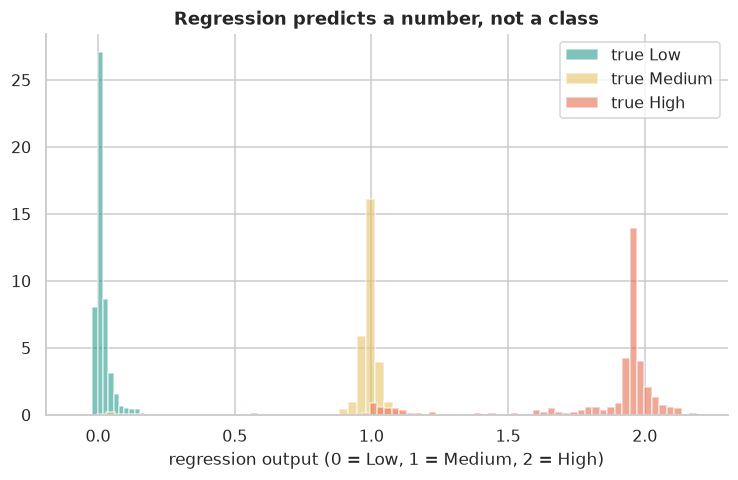

In [2]:
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import balanced_accuracy_score

irr = data.sample(30_000, seed=4)
y_irr = irr[data.TARGET].cat.codes.to_numpy()
tr, te, ytr, yte = train_test_split(irr, y_irr, test_size=0.3, stratify=y_irr, random_state=0)
clf = preprocess.pipeline(HistGradientBoostingClassifier(random_state=0), scale=None).fit(tr, ytr)
reg = preprocess.pipeline(HistGradientBoostingRegressor(random_state=0), scale=None).fit(tr, ytr)
raw = reg.predict(te)
print("classifier balanced accuracy:            ", round(balanced_accuracy_score(yte, clf.predict(te)), 4))
print("regressor, rounded, balanced accuracy:   ", round(balanced_accuracy_score(yte, np.clip(np.round(raw), 0, 2)), 4))

fig, ax = plt.subplots()
for k, cls in enumerate(data.CLASSES):
    ax.hist(raw[yte == k], bins=60, alpha=0.6, density=True, color=plotting.CLASS_COLORS[cls], label=f"true {cls}")
ax.set(xlabel="regression output (0 = Low, 1 = Medium, 2 = High)", title="Regression predicts a number, not a class")
ax.legend()
plotting.save("i04-reg-vs-clf")
plt.show()

The rounded regressor actually scores a little *higher* here (0.954 against 0.945). Treating the target as a number uses the order Low < Medium < High, which a classifier ignores, and rounding at 0.5 and 1.5 happens to place the boundaries in a way that suits balanced accuracy. That is a preview of the decision-threshold tuning in notebook 05. Still, regression is the natural tool when the target is a true quantity, like a yield, and that is what the rest of this notebook works on.

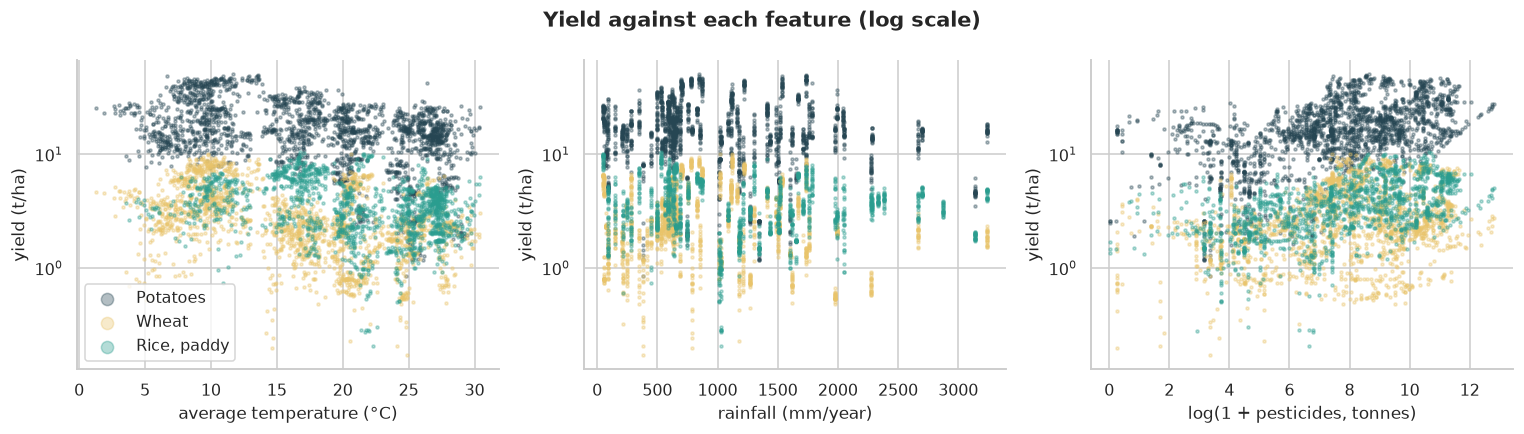

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, label in zip(axes, ["temp_c", "rain_mm", "log_pesticides"], ["average temperature (°C)", "rainfall (mm/year)", "log(1 + pesticides, tonnes)"]):
    for crop, color in [("Potatoes", "#264653"), ("Wheat", "#e9c46a"), ("Rice, paddy", "#2a9d8f")]:
        part = yd[yd["crop"] == crop]
        ax.scatter(part[col], part["yield_t_ha"], s=4, alpha=0.35, color=color, label=crop)
    ax.set(xlabel=label, ylabel="yield (t/ha)", yscale="log")
axes[0].legend(markerscale=4)
fig.suptitle("Yield against each feature (log scale)", fontweight="bold")
fig.tight_layout()
plotting.save("i04-yield-eda")
plt.show()

## 2. Bias–variance considerations in regression
With one feature (temperature) and one crop (wheat), polynomials of growing degree go from too rigid (high bias) to too wiggly (high variance). Error is measured by 5-fold cross-validation:

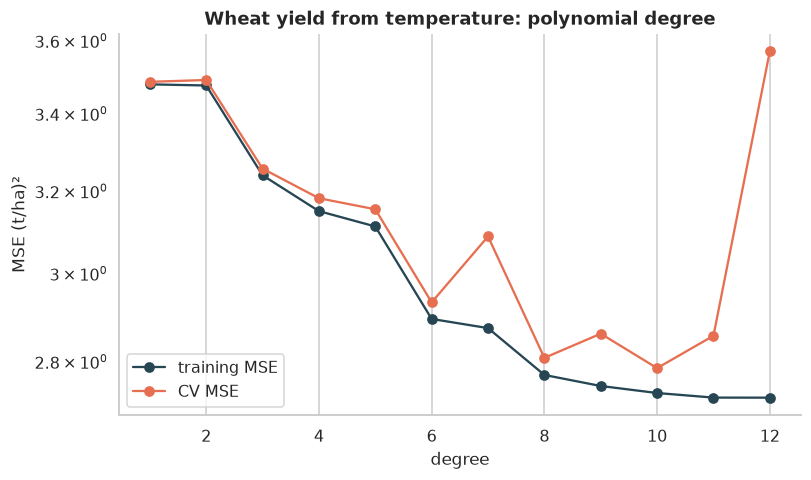

,training MSE,CV MSE
degree,,
1,3.478,3.485
2,3.475,3.490
3,3.239,3.256
4,3.149,3.181
5,3.112,3.154
6,2.894,2.932
7,2.874,3.088
8,2.770,2.808
9,2.746,2.861


In [4]:
wheat = yd[yd["crop"] == "Wheat"]
Xw, yw = wheat[["temp_c"]].to_numpy(), wheat["yield_t_ha"].to_numpy()
cv = KFold(5, shuffle=True, random_state=0)
rows = []
for deg in range(1, 13):
    model = make_pipeline(StandardScaler(), PolynomialFeatures(deg), StandardScaler(), LinearRegression())
    train_mse = mean_squared_error(yw, model.fit(Xw, yw).predict(Xw))
    cv_mse = -cross_val_score(model, Xw, yw, cv=cv, scoring="neg_mean_squared_error").mean()
    rows.append({"degree": deg, "training MSE": train_mse, "CV MSE": cv_mse})
bv = pd.DataFrame(rows).set_index("degree")
ax = bv.plot(marker="o", color=[plotting.ACCENT, "#e76f51"])
ax.set(ylabel="MSE (t/ha)²", title="Wheat yield from temperature: polynomial degree", yscale="log")
plotting.save("i04-bias-variance")
plt.show()
bv.round(3)

Training error can only go down as the degree rises; cross-validated error falls, flattens, then climbs once the curve starts chasing noise.

## 3. Simple linear regression (SLR)
One feature, a straight line: *ŷ = β₀ + β₁x*, fitted by least squares. The closed form β₁ = cov(x, y) / var(x) is checked against statsmodels:

by hand:      yield = 5.215 + (-0.1303) × temperature
statsmodels:  yield = 5.215 + (-0.1303) × temperature,  R² = 0.186


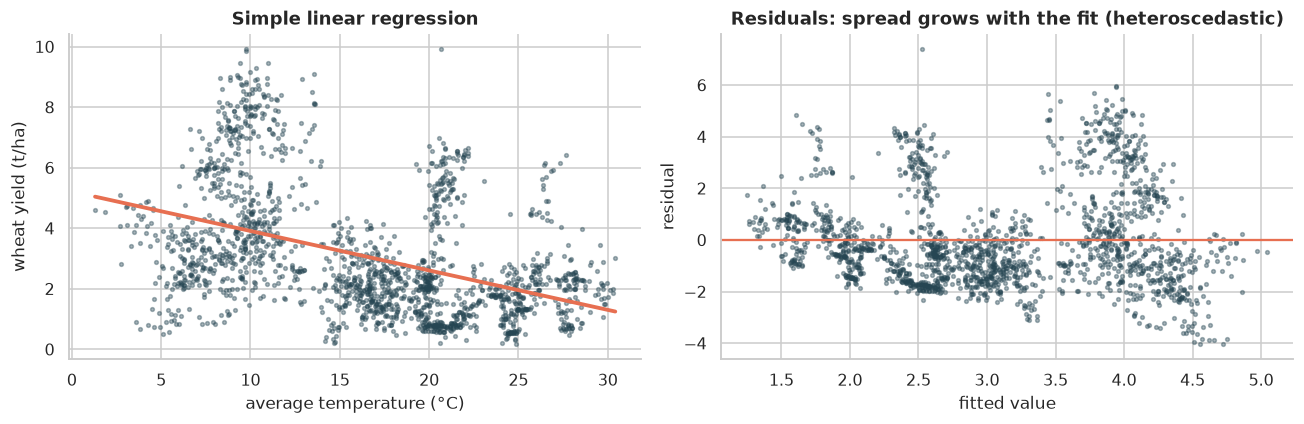

In [5]:
x = wheat["temp_c"]
y_ = wheat["yield_t_ha"]
b1 = np.cov(x, y_)[0, 1] / x.var()
b0 = y_.mean() - b1 * x.mean()
slr = smf.ols("yield_t_ha ~ temp_c", data=wheat).fit()
print(f"by hand:      yield = {b0:.3f} + ({b1:.4f}) × temperature")
print(f"statsmodels:  yield = {slr.params['Intercept']:.3f} + ({slr.params['temp_c']:.4f}) × temperature,  R² = {slr.rsquared:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(x, y_, s=6, alpha=0.4, color=plotting.ACCENT)
grid = np.linspace(x.min(), x.max(), 100)
axes[0].plot(grid, b0 + b1 * grid, color="#e76f51", lw=2.5)
axes[0].set(xlabel="average temperature (°C)", ylabel="wheat yield (t/ha)", title="Simple linear regression")
axes[1].scatter(slr.fittedvalues, slr.resid, s=6, alpha=0.4, color=plotting.ACCENT)
axes[1].axhline(0, color="#e76f51")
axes[1].set(xlabel="fitted value", ylabel="residual", title="Residuals: spread grows with the fit (heteroscedastic)")
fig.tight_layout()
plotting.save("i04-slr")
plt.show()

Wheat yields fall by about 0.13 t/ha for every extra degree of average temperature: hot countries grow less wheat per hectare. But R² is only 0.19, and the residuals fan out, so one feature on the raw scale is far from the whole story.

## 4. Multiple linear regression (MLR)
Several features at once. Yield is modelled on the **log** scale (it spans 0.1–50 t/ha and its noise is multiplicative), with rainfall, temperature, log pesticide use and crop type:

In [6]:
mlr = smf.ols("log_yield ~ rain_mm + temp_c + log_pesticides + C(crop)", data=yd).fit()
print(f"R² = {mlr.rsquared:.3f}, adjusted R² = {mlr.rsquared_adj:.3f}, n = {int(mlr.nobs):,}")
mlr.summary().tables[1]

R² = 0.683, adjusted R² = 0.682, n = 13,130


,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,1.9349,0.038,50.536,0.000,1.860,2.010
C(crop)[T.Maize],-1.3678,0.026,-53.496,0.000,-1.418,-1.318
C(crop)[T.Plantains and others],0.0695,0.036,1.923,0.055,-0.001,0.140
C(crop)[T.Potatoes],0.3735,0.026,14.516,0.000,0.323,0.424
"C(crop)[T.Rice, paddy]",-1.1258,0.027,-42.189,0.000,-1.178,-1.073
C(crop)[T.Sorghum],-2.0398,0.027,-75.372,0.000,-2.093,-1.987
C(crop)[T.Soybeans],-2.0976,0.028,-74.646,0.000,-2.153,-2.043
C(crop)[T.Sweet potatoes],-0.1607,0.028,-5.741,0.000,-0.216,-0.106
C(crop)[T.Wheat],-1.5176,0.027,-56.889,0.000,-1.570,-1.465
C(crop)[T.Yams],0.1324,0.036,3.642,0.000,0.061,0.204


## 5. Interpretation of coefficients
Each coefficient is the change in the target for a one-unit change in that feature, **holding the others fixed**. On a log target, a coefficient β means a change of about (e^β − 1) × 100% in yield:

In [7]:
interp = pd.DataFrame({"coefficient": mlr.params, "p-value": mlr.pvalues})
interp["effect on yield"] = [f"{(np.exp(b) - 1) * 100:+.1f}%" for b in interp["coefficient"]]
interp.loc[["temp_c", "rain_mm", "log_pesticides"], "per"] = ["+1 °C", "+1 mm of rain", "+1 in log pesticides (×2.7 tonnes)"]
interp.loc[["temp_c", "rain_mm", "log_pesticides"] + [i for i in interp.index if i.startswith("C(crop)")][:4]].round(5)

,coefficient,p-value,effect on yield,per
temp_c,-0.02376,0.00000,-2.3%,+1 °C
rain_mm,0.00001,0.10373,+0.0%,+1 mm of rain
log_pesticides,0.11087,0.00000,+11.7%,+1 in log pesticides (×2.7 tonnes)
C(crop)[T.Maize],-1.36778,0.00000,-74.5%,NaN
C(crop)[T.Plantains and others],0.06946,0.05452,+7.2%,NaN
C(crop)[T.Potatoes],0.37348,0.00000,+45.3%,NaN
"C(crop)[T.Rice, paddy]",-1.12575,0.00000,-67.6%,NaN


Each extra degree of average temperature goes with a few percent less yield, holding crop, rain and pesticides fixed. More pesticide use goes with higher yield, but that is an **association**: richer, more intensive farming systems use more of everything. The crop dummies are relative to the baseline crop (cassava): potatoes and plantains yield more tonnes per hectare, cereals fewer. That's a fact about the crops, not the farming.

## 6. Polynomial feature expansion
Crops have an optimum temperature: too cold and too hot both hurt. A straight line can't express that; adding temperature² lets the model bend:

In [8]:
quad = smf.ols("log_yield ~ rain_mm + temp_c + I(temp_c**2) + log_pesticides + C(crop)", data=yd).fit()
print(f"linear in temperature:    adjusted R² {mlr.rsquared_adj:.4f}, AIC {mlr.aic:,.0f}")
print(f"with temperature²:        adjusted R² {quad.rsquared_adj:.4f}, AIC {quad.aic:,.0f}")
b_t, b_t2 = quad.params["temp_c"], quad.params["I(temp_c ** 2)"]
print(f"implied optimum temperature: {-b_t / (2 * b_t2):.1f} °C")

linear in temperature:    adjusted R² 0.6823, AIC 25,385
with temperature²:        adjusted R² 0.6869, AIC 25,194
implied optimum temperature: 24.0 °C


## 7. Regularised regression models
With many features (here: all countries as dummies, plus degree-2 interactions of the numeric features) ordinary least squares overfits and its coefficients become unstable. Regularisation adds a penalty on the size of the weights:
- **Ridge (L2):** penalty λΣβ²: shrinks all weights smoothly; keeps every feature.
- **Lasso (L1):** penalty λΣ|β|: drives some weights to exactly zero, so it selects features.
- **Elastic Net:** a mix of both; useful when features come in correlated groups.

Countries never seen in training would make the test meaningless, so cross-validation groups by country: each fold predicts *whole countries* it has never seen.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.preprocessing import OneHotEncoder

num_cols = ["rain_mm", "temp_c", "log_pesticides", "year"]
expand = ColumnTransformer([
    ("num", make_pipeline(StandardScaler(), PolynomialFeatures(3, include_bias=False), StandardScaler()), num_cols),
    ("crop", OneHotEncoder(drop="first", sparse_output=False), ["crop"]),
])
Xy, yy, groups = yd[num_cols + ["crop"]], yd["log_yield"], yd["country"]
gcv = GroupKFold(5)
print("expanded features:", expand.fit_transform(Xy).shape[1])

rows = []
for name, model in [("OLS (no penalty)", LinearRegression()), ("Ridge, λ = 10", Ridge(10)), ("Lasso, λ = 0.005", Lasso(0.005, max_iter=20000)),
                    ("Elastic Net, λ = 0.01, 50% L1", ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=20000))]:
    pipe = make_pipeline(expand, model)
    sc = cross_val_score(pipe, Xy, yy, groups=groups, cv=gcv, scoring="r2")
    coefs = pipe.fit(Xy, yy)[-1].coef_
    rows.append({"model": name, "CV R² (unseen countries)": sc.mean(), "non-zero coefficients": int((np.abs(coefs) > 1e-8).sum()),
                 "largest |coefficient|": np.abs(coefs).max()})
pd.DataFrame(rows).round(4)

expanded features: 43


,model,CV R² (unseen countries),non-zero coefficients,largest |coefficient|
0,OLS (no penalty),0.6436,43,2.1454
1,"Ridge, λ = 10",0.6455,43,2.0433
2,"Lasso, λ = 0.005",0.6843,32,1.8774
3,"Elastic Net, λ = 0.01, 50% L1",0.6736,33,1.5670


## 8. Effect of regularisation on model complexity
Sweeping λ shows the trade-off directly. Small λ: complex model, coefficients large; large λ: simple model, coefficients shrink towards zero (Ridge) or vanish (Lasso).

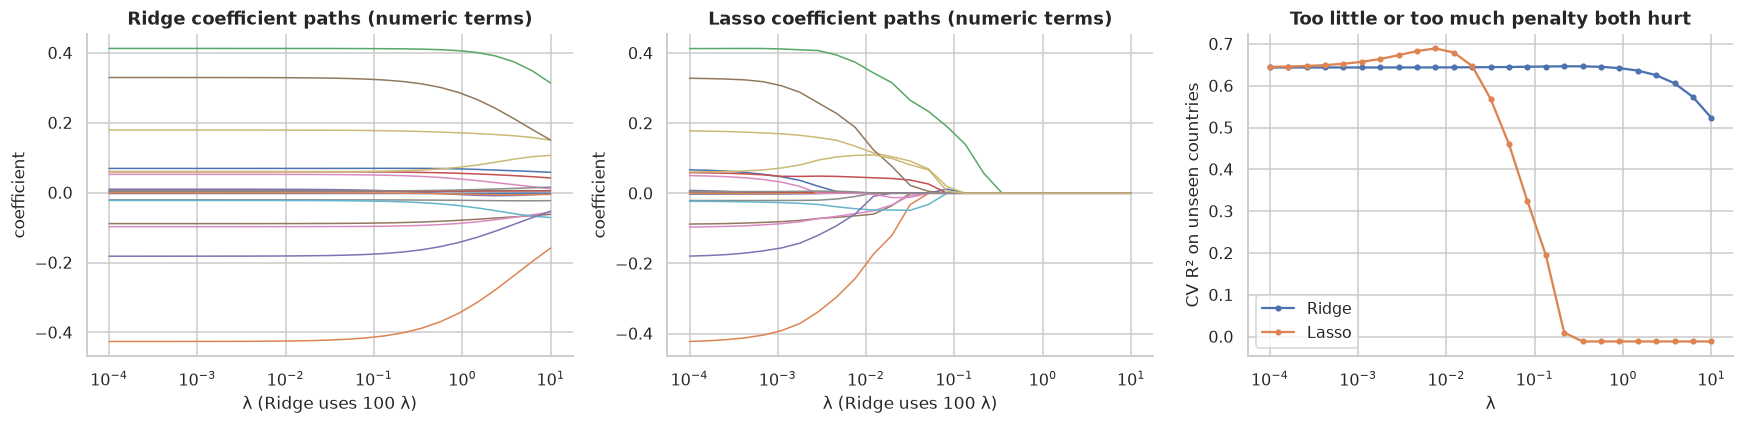

In [10]:
lams = np.logspace(-4, 1, 25)
Xe = expand.fit_transform(Xy)
paths = {"Ridge": [], "Lasso": []}
cv_r2 = {"Ridge": [], "Lasso": []}
for lam in lams:
    for name, model in [("Ridge", Ridge(lam * 100)), ("Lasso", Lasso(lam, max_iter=20000))]:
        paths[name].append(model.fit(Xe, yy).coef_)
        cv_r2[name].append(cross_val_score(make_pipeline(expand, model), Xy, yy, groups=groups, cv=gcv, scoring="r2").mean())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, name in zip(axes[:2], ["Ridge", "Lasso"]):
    ax.plot(lams, np.array(paths[name])[:, :19], lw=1)
    ax.set(xscale="log", xlabel="λ (Ridge uses 100 λ)", ylabel="coefficient", title=f"{name} coefficient paths (numeric terms)")
axes[2].plot(lams, cv_r2["Ridge"], "o-", ms=3, label="Ridge")
axes[2].plot(lams, cv_r2["Lasso"], "o-", ms=3, label="Lasso")
axes[2].set(xscale="log", xlabel="λ", ylabel="CV R² on unseen countries", title="Too little or too much penalty both hurt")
axes[2].legend()
fig.tight_layout()
plotting.save("i04-regularisation")
plt.show()

## 9. Tree-based regression models
Trees split the data into boxes and predict the mean yield in each box, so they find non-linear effects and interactions without any polynomial terms. On the same unseen-country cross-validation:

In [11]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

tree_cols = ColumnTransformer([("num", "passthrough", num_cols), ("crop", OneHotEncoder(sparse_output=False), ["crop"])])
rows = []
for name, model in [("Linear regression (+ crop)", LinearRegression()), ("Decision tree (depth 8)", DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=0)),
                    ("Random forest", RandomForestRegressor(300, min_samples_leaf=3, n_jobs=-1, random_state=0)),
                    ("Gradient boosting", HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=0))]:
    pipe = make_pipeline(tree_cols, model)
    r2 = cross_val_score(pipe, Xy, yy, groups=groups, cv=gcv, scoring="r2")
    mae = -cross_val_score(pipe, Xy, yy, groups=groups, cv=gcv, scoring="neg_mean_absolute_error")
    rows.append({"model": name, "CV R²": r2.mean(), "CV MAE (log units)": mae.mean(), "≈ typical error": f"×{np.exp(mae.mean()):.2f}"})
tree_table = pd.DataFrame(rows)
tree_table.round(4)

,model,CV R²,CV MAE (log units),≈ typical error
0,Linear regression (+ crop),0.6731,0.4847,×1.62
1,Decision tree (depth 8),0.6153,0.5209,×1.68
2,Random forest,0.6303,0.4995,×1.65
3,Gradient boosting,0.6566,0.4864,×1.63


A log-scale MAE of *m* means predictions are typically off by a factor of eᵐ. The result goes against the usual expectation: on countries they have never seen, the tree models do *not* beat linear regression with crop dummies (R² 0.673). Trees predict the average of training boxes, so they can't extrapolate to a new country whose climate or farming system sits outside what they saw, while the linear model's smooth trends carry over. Gradient boosting comes closest (0.657). On new years of *known* countries the ranking would be different; what you validate on decides what "best" means.

## 10. Time-series regression models
Yields change over time (better seeds, more fertiliser, more irrigation), so a model that ignores time leaks the future into the past. The rule for time series: **train on the past, test on the future**, never shuffle. Below: average yield per crop worldwide, 1990–2013, train on 1990–2007, forecast 2008–2013. Three models:
1. **naive:** next year = this year;
2. **trend regression:** yield = a + b·year;
3. **autoregression with a trend:** yield(t) = a + b·year + c·yield(t−1) + d·yield(t−2), fitted with least squares on lagged copies of the series.

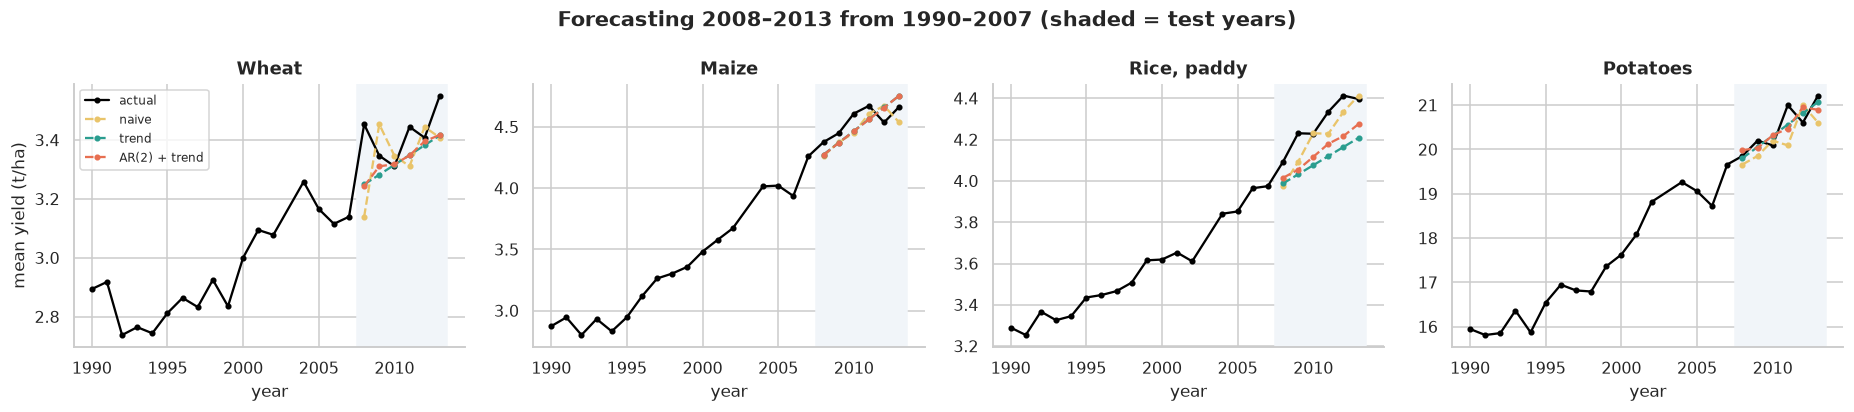

model,AR(2) + trend,naive,trend
crop,,,
Maize,0.108,0.113,0.107
Potatoes,0.287,0.425,0.200
"Rice, paddy",0.140,0.077,0.185
Wheat,0.083,0.128,0.088
mean,0.154,0.186,0.145


In [12]:
world = yd.groupby(["crop", "year"])["yield_t_ha"].mean().unstack(0)
crops = ["Wheat", "Maize", "Rice, paddy", "Potatoes"]
train_end = 2007
rows = []
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, crop in zip(axes, crops):
    s_ = world[crop].dropna()
    frame = pd.DataFrame({"y": s_, "lag1": s_.shift(1), "lag2": s_.shift(2), "year": s_.index}).dropna()
    tr_f, te_f = frame[frame.year <= train_end], frame[frame.year > train_end]
    preds = {
        "naive": te_f["lag1"].to_numpy(),
        "trend": LinearRegression().fit(tr_f[["year"]], tr_f["y"]).predict(te_f[["year"]]),
        "AR(2) + trend": LinearRegression().fit(tr_f[["year", "lag1", "lag2"]], tr_f["y"]).predict(te_f[["year", "lag1", "lag2"]]),
    }
    ax.plot(s_.index, s_, "o-", ms=3, color="black", label="actual")
    ax.axvspan(train_end + 0.5, 2013.5, color="#f1f5f9")
    for (name, p), color in zip(preds.items(), ["#e9c46a", "#2a9d8f", "#e76f51"]):
        ax.plot(te_f.year, p, "o--", ms=3, color=color, label=name)
        rows.append({"crop": crop, "model": name, "MAE 2008–2013 (t/ha)": mean_absolute_error(te_f["y"], p)})
    ax.set(title=crop, xlabel="year")
axes[0].set_ylabel("mean yield (t/ha)")
axes[0].legend(fontsize=8)
fig.suptitle("Forecasting 2008–2013 from 1990–2007 (shaded = test years)", fontweight="bold")
fig.tight_layout()
plotting.save("i04-timeseries")
plt.show()
ts = pd.DataFrame(rows).pivot(index="crop", columns="model", values="MAE 2008–2013 (t/ha)")
ts.loc["mean"] = ts.mean()
ts.round(3)

On average the plain trend line is the most accurate forecast (mean MAE 0.145 t/ha), with the trend + AR(2) model close behind (0.154) and the naive forecast last (0.186). The winner changes by crop: AR helps for wheat, the naive forecast is best for rice. With only 16 training years per series, simple models are hard to beat.

Shuffled cross-validation would be wrong here. `TimeSeriesSplit` is the scikit-learn tool that keeps the order: each fold trains on everything before a cut-off and tests on the block after it.

In [13]:
from sklearn.model_selection import TimeSeriesSplit

s_ = world["Wheat"].dropna()
frame = pd.DataFrame({"y": s_, "lag1": s_.shift(1), "lag2": s_.shift(2), "year": s_.index}).dropna()
for k, (tr_i, te_i) in enumerate(TimeSeriesSplit(n_splits=4).split(frame)):
    print(f"fold {k + 1}: train {frame.year.iloc[tr_i].min()}–{frame.year.iloc[tr_i].max()}, test {frame.year.iloc[te_i].min()}–{frame.year.iloc[te_i].max()}")

fold 1: train 1992–1996, test 1997–2000
fold 2: train 1992–2000, test 2001–2005
fold 3: train 1992–2005, test 2006–2009
fold 4: train 1992–2009, test 2010–2013


| Syllabus topic | Where |
|---|---|
| Regression vs classification | 1 |
| Bias–variance in regression | 2 |
| Simple and multiple linear regression | 3, 4 |
| Interpretation of coefficients | 5 |
| Polynomial feature expansion | 6 |
| Ridge, Lasso, Elastic Net | 7 |
| Effect of regularisation on complexity | 8 |
| Tree-based regression | 9 |
| Time-series regression | 10 |